## 1. 데이터 파일 경로 설정 및 파일 존재 여부 확인

Google Drive에 저장된 훈련용·검증용 CSV 파일의 경로를 설정한다.  
또한 지정한 경로에 파일이 실제로 존재하는지 확인한다.


## 2. CSV 데이터 불러오기 및 데이터 구조 확인

훈련용·검증용 CSV 파일을 각각 `train_df`, `val_df`로 불러온다.  
데이터의 행과 열 개수를 확인하고, 훈련 데이터의 앞부분을 출력하여 컬럼과 값이 정상적으로 불러와졌는지 확인한다.

In [7]:
# ============================================================
# 1. 필요한 라이브러리 설치 및 불러오기
# ============================================================

!pip install -q gdown

import os
import glob
import shutil
import zipfile

import gdown
import pandas as pd
from IPython.display import display


# ============================================================
# 2. 설정
# ============================================================

TRAIN_URL = (
    "https://drive.google.com/uc?id="
    "1xtQ2kR2CbQL79sFidSHVHCGjktGSUYOS"
)

VAL_URL = (
    "https://drive.google.com/uc?id="
    "1kIsxMZmh8LqCm800lhtc3OaKudEZcnI3"
)

TRAIN_ZIP = "/content/train_data.zip"
VAL_ZIP = "/content/val_data.zip"

TRAIN_DIR = "/content/train_unzipped"
VAL_DIR = "/content/val_unzipped"


# ============================================================
# 3. 기존 압축 해제 폴더 초기화
# ============================================================

for folder in [TRAIN_DIR, VAL_DIR]:
    if os.path.exists(folder):
        shutil.rmtree(folder)

    os.makedirs(folder, exist_ok=True)

print("✅ 압축 해제 폴더 준비 완료")


# ============================================================
# 4. Google Drive에서 ZIP 파일 다운로드
# ============================================================

print("\n📥 Train 데이터 다운로드 중...")

train_download_result = gdown.download(
    url=TRAIN_URL,
    output=TRAIN_ZIP,
    quiet=False,
    fuzzy=True,
)

print("\n📥 Validation 데이터 다운로드 중...")

val_download_result = gdown.download(
    url=VAL_URL,
    output=VAL_ZIP,
    quiet=False,
    fuzzy=True,
)

if train_download_result is None:
    raise RuntimeError(
        "Train 파일 다운로드에 실패했습니다. "
        "Google Drive 파일의 공유 권한을 확인해 주세요."
    )

if val_download_result is None:
    raise RuntimeError(
        "Validation 파일 다운로드에 실패했습니다. "
        "Google Drive 파일의 공유 권한을 확인해 주세요."
    )

print("\n✅ 데이터 다운로드 완료")


# ============================================================
# 5. 다운로드된 파일이 정상적인 ZIP인지 확인
# ============================================================

if not zipfile.is_zipfile(TRAIN_ZIP):
    raise ValueError(
        f"{TRAIN_ZIP} 파일이 정상적인 ZIP 파일이 아닙니다. "
        "Google Drive 공유 권한 또는 다운로드 링크를 확인해 주세요."
    )

if not zipfile.is_zipfile(VAL_ZIP):
    raise ValueError(
        f"{VAL_ZIP} 파일이 정상적인 ZIP 파일이 아닙니다. "
        "Google Drive 공유 권한 또는 다운로드 링크를 확인해 주세요."
    )

print("✅ ZIP 파일 확인 완료")


# ============================================================
# 6. ZIP 파일 압축 해제
# ============================================================

print("\n📦 Train 데이터 압축 해제 중...")

with zipfile.ZipFile(TRAIN_ZIP, "r") as zip_ref:
    zip_ref.extractall(TRAIN_DIR)

print("📦 Validation 데이터 압축 해제 중...")

with zipfile.ZipFile(VAL_ZIP, "r") as zip_ref:
    zip_ref.extractall(VAL_DIR)

print("✅ 압축 해제 완료")


# ============================================================
# 7. 모든 하위 폴더에서 CSV 파일 검색
# ============================================================

train_files = sorted(
    glob.glob(
        os.path.join(TRAIN_DIR, "**", "*.csv"),
        recursive=True,
    )
)

val_files = sorted(
    glob.glob(
        os.path.join(VAL_DIR, "**", "*.csv"),
        recursive=True,
    )
)

print(f"\n🔍 감지된 Train CSV 파일: {len(train_files)}개")
print(f"🔍 감지된 Validation CSV 파일: {len(val_files)}개")


# 검색한 파일 일부 출력
print("\n[Train CSV 파일 예시]")

for file_path in train_files[:5]:
    print(file_path)

print("\n[Validation CSV 파일 예시]")

for file_path in val_files[:5]:
    print(file_path)


# CSV가 발견되지 않았으면 실행 중단
if not train_files:
    raise FileNotFoundError(
        f"{TRAIN_DIR} 및 하위 폴더에서 CSV 파일을 찾지 못했습니다."
    )

if not val_files:
    raise FileNotFoundError(
        f"{VAL_DIR} 및 하위 폴더에서 CSV 파일을 찾지 못했습니다."
    )


# ============================================================
# 8. CSV 인코딩을 자동으로 처리하는 함수
# ============================================================

def read_csv_safely(file_path):
    """
    UTF-8 계열로 먼저 읽고, 실패하면 CP949와 EUC-KR을 시도합니다.
    """

    encodings = [
        "utf-8",
        "utf-8-sig",
        "cp949",
        "euc-kr",
    ]

    last_error = None

    for encoding in encodings:
        try:
            return pd.read_csv(
                file_path,
                encoding=encoding,
                low_memory=False,
            )
        except UnicodeDecodeError as error:
            last_error = error

    raise UnicodeDecodeError(
        last_error.encoding,
        last_error.object,
        last_error.start,
        last_error.end,
        f"CSV 인코딩을 확인할 수 없습니다: {file_path}",
    )


# ============================================================
# 9. CSV 파일 읽기 및 병합
# ============================================================

print("\n📊 Train CSV 파일을 읽는 중...")

train_df_list = []

for index, file_path in enumerate(train_files, start=1):
    print(
        f"[Train {index}/{len(train_files)}] "
        f"{os.path.basename(file_path)}"
    )

    current_df = read_csv_safely(file_path)

    # 어떤 파일에서 온 데이터인지 확인할 수 있도록 기록
    current_df["source_file"] = os.path.basename(file_path)

    train_df_list.append(current_df)


print("\n📊 Validation CSV 파일을 읽는 중...")

val_df_list = []

for index, file_path in enumerate(val_files, start=1):
    print(
        f"[Validation {index}/{len(val_files)}] "
        f"{os.path.basename(file_path)}"
    )

    current_df = read_csv_safely(file_path)
    current_df["source_file"] = os.path.basename(file_path)

    val_df_list.append(current_df)


# 파일별 컬럼이 조금 달라도 병합 가능하도록 sort=False 사용
train_df = pd.concat(
    train_df_list,
    ignore_index=True,
    sort=False,
)

val_df = pd.concat(
    val_df_list,
    ignore_index=True,
    sort=False,
)

print("\n🎉 CSV 병합 완료")


# ============================================================
# 10. 병합 결과 확인
# ============================================================

print("\n========== 데이터 크기 ==========")
print("Train 데이터 크기:", train_df.shape)
print("Validation 데이터 크기:", val_df.shape)

print("\n========== Train 컬럼 ==========")
print(train_df.columns.tolist())

print("\n========== Validation 컬럼 ==========")
print(val_df.columns.tolist())

print("\n========== Train 데이터 앞 3행 ==========")
display(train_df.head(3))

print("\n========== Validation 데이터 앞 3행 ==========")
display(val_df.head(3))

print("\n========== Train 데이터 정보 ==========")
train_df.info()

print("\n========== Validation 데이터 정보 ==========")
val_df.info()


# ============================================================
# 11. 결측치 개수 확인
# ============================================================

print("\n========== Train 결측치 상위 20개 컬럼 ==========")

display(
    train_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_count")
)

print("\n========== Validation 결측치 상위 20개 컬럼 ==========")

display(
    val_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_count")
)


# ============================================================
# 12. 필요하면 병합 결과를 CSV로 저장
# ============================================================

TRAIN_OUTPUT = "/content/merged_train.csv"
VAL_OUTPUT = "/content/merged_validation.csv"

train_df.to_csv(
    TRAIN_OUTPUT,
    index=False,
    encoding="utf-8-sig",
)

val_df.to_csv(
    VAL_OUTPUT,
    index=False,
    encoding="utf-8-sig",
)

print("\n💾 병합된 데이터 저장 완료")
print("Train 저장 위치:", TRAIN_OUTPUT)
print("Validation 저장 위치:", VAL_OUTPUT)

✅ 압축 해제 폴더 준비 완료

📥 Train 데이터 다운로드 중...


Downloading...
From (original): https://drive.google.com/uc?id=1xtQ2kR2CbQL79sFidSHVHCGjktGSUYOS
From (redirected): https://drive.google.com/uc?id=1xtQ2kR2CbQL79sFidSHVHCGjktGSUYOS&confirm=t&uuid=2f61efa3-1e18-4601-bef1-dd3540bdf45a
To: /content/train_data.zip
100%|██████████| 45.5M/45.5M [00:01<00:00, 42.2MB/s]



📥 Validation 데이터 다운로드 중...


Downloading...
From: https://drive.google.com/uc?id=1kIsxMZmh8LqCm800lhtc3OaKudEZcnI3
To: /content/val_data.zip
100%|██████████| 5.71M/5.71M [00:00<00:00, 18.5MB/s]



✅ 데이터 다운로드 완료
✅ ZIP 파일 확인 완료

📦 Train 데이터 압축 해제 중...
📦 Validation 데이터 압축 해제 중...
✅ 압축 해제 완료

🔍 감지된 Train CSV 파일: 16개
🔍 감지된 Validation CSV 파일: 16개

[Train CSV 파일 예시]
/content/train_unzipped/TL_카드거래/21-2_카드데이터_2021_1분기.csv
/content/train_unzipped/TL_카드거래/21-2_카드데이터_2021_2분기.csv
/content/train_unzipped/TL_카드거래/21-2_카드데이터_2021_3분기.csv
/content/train_unzipped/TL_카드거래/21-2_카드데이터_2021_4분기.csv
/content/train_unzipped/TL_카드거래/21-2_카드데이터_2022_1분기.csv

[Validation CSV 파일 예시]
/content/val_unzipped/VL_카드거래/21-2_카드데이터_2021_1분기.csv
/content/val_unzipped/VL_카드거래/21-2_카드데이터_2021_2분기.csv
/content/val_unzipped/VL_카드거래/21-2_카드데이터_2021_3분기.csv
/content/val_unzipped/VL_카드거래/21-2_카드데이터_2021_4분기.csv
/content/val_unzipped/VL_카드거래/21-2_카드데이터_2022_1분기.csv

📊 Train CSV 파일을 읽는 중...
[Train 1/16] 21-2_카드데이터_2021_1분기.csv
[Train 2/16] 21-2_카드데이터_2021_2분기.csv
[Train 3/16] 21-2_카드데이터_2021_3분기.csv
[Train 4/16] 21-2_카드데이터_2021_4분기.csv
[Train 5/16] 21-2_카드데이터_2022_1분기.csv
[Train 6/16] 21-2_카드데이터_2022_2분기.csv
[Train 7/16] 

,기준년월,승인일자,승인SEQ,승인시간대,카드KEY,통합승인금액,개인법인구분코드_회원,국내해외여부,카드이용한도금액,가맹점광역시도코드,...,가맹점상태코드,가맹점형태구분코드,로고구분코드,일시불할부구분코드,전월_매출건수,카드구분코드,할부가능개월수,가맹점KEY,전월_매출금액,source_file
0,202102,20210207,2,9,CD001231,8000,1.0,0,10000000.0,13.0,...,30.0,00,2,A,48.0,1,24.0,ST001180,1350000.0,21-2_카드데이터_2021_1분기.csv
1,202102,20210219,17,17,CD000104,19000,1.0,0,0.0,13.0,...,30.0,00,2,A,55.0,1,24.0,ST000266,1894000.0,21-2_카드데이터_2021_1분기.csv
2,202101,20210111,8,12,CD000965,8000,1.0,0,5000000.0,9.0,...,30.0,00,1,A,53.0,1,24.0,ST000375,1575000.0,21-2_카드데이터_2021_1분기.csv


... (3 outputs left out)

,missing_count
이상거래유형,1671878
이상거래설명,1671878
개인법인구분코드_가맹점,25939
가맹점광역시도코드,25939
가맹점여부_신규,25939
인터넷판매여부,25939
전월_매출건수,13673
전월_매출금액,12886
할부가능개월수,11336
가맹점형태구분코드,10929



========== Validation 결측치 상위 20개 컬럼 ==========


,missing_count
이상거래유형,208985
이상거래설명,208985
개인법인구분코드_가맹점,3237
가맹점광역시도코드,3237
가맹점여부_신규,3237
인터넷판매여부,3237
전월_매출건수,1647
전월_매출금액,1561
할부가능개월수,1385
가맹점형태구분코드,1336



💾 병합된 데이터 저장 완료
Train 저장 위치: /content/merged_train.csv
Validation 저장 위치: /content/merged_validation.csv


## 3. 데이터 통합 및 Train / Validation / Test 분리

기존 Training 데이터와 Validation 데이터를 하나로 합친 후,  
타깃 변수인 `이상거래여부`의 클래스 비율을 유지하면서 데이터를 분리합니다.

- **Training 데이터:** 70%
- **Validation 데이터:** 10%
- **Test 데이터:** 20%
- **분할 기준:** `이상거래여부`
- **Random State:** 42

In [8]:
# 3번 셀만 수정

from sklearn.model_selection import train_test_split

# Training과 기존 Validation 데이터 결합
all_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Test 20% 분리
train_valid_df, test_df = train_test_split(
    all_df,
    test_size=0.20,
    stratify=all_df["이상거래여부"],
    random_state=42
)

# 남은 데이터에서 Validation 12.5% 분리
# 최종 비율: Train 70% / Validation 10% / Test 20%
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.125,
    stratify=train_valid_df["이상거래여부"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)

(1367009, 33)
(195287, 33)
(390575, 33)




### 데이터 누수 방지 원칙

- 결측치 대체에 사용하는 중앙값은 Train 데이터에서만 계산한다.
- 카드별 평균 승인금액도 Train 데이터에서만 계산한다.
- RobustScaler는 Train 데이터로만 학습한 뒤 Test 데이터에 적용한다.
- SMOTENC는 Train 데이터에만 적용한다.
- Test 데이터에는 오버샘플링을 적용하지 않고 원본 클래스 분포를 유지한다.

### 결론

Train 데이터는 모델 학습에 사용하고, Test 데이터는 학습 과정에서 사용하지 않은 최종 평가 데이터로 활용한다. 이를 통해 모델이 학습하지 않은 새로운 거래에서도 이상거래를 탐지할 수 있는지 확인한다.

## 4. 입력·정답 데이터 분리 및 데이터 누수 방지

모델 학습에 사용할 입력 변수(`X`)와 모델이 예측해야 하는 정답(`y`)을 분리한다.

`이상거래유형`과 `이상거래설명`은 이상거래 여부를 직접적으로 암시할 수 있으므로 모델 입력에서 제외한다. 이러한 컬럼이 포함되면 모델이 거래 특징이 아닌 정답 정보를 이용하게 되어 데이터 누수가 발생할 수 있다.

현재 선택한 원본 변수는 승인금액, 카드 이용한도, 거래시간, 국내외 여부 등 실제 거래 시점에 확인할 수 있는 정보로 구성하였다.

마지막으로 `assert`를 이용하여 정답 및 누수 위험 컬럼이 모델 입력에 포함되지 않았는지 확인한다.

In [9]:
### 정답 분리 및 누수 컬럼 제외

# 정답 컬럼 이름을 먼저 지정한다.
TARGET = "이상거래여부"

# 정답을 직접 암시하는 컬럼을 제외한다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]

# 파생변수 생성에 사용할 원본 변수이다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
]

# 입력 변수 분리
X_train_raw = train_df[SOURCE_FEATURES].copy()
X_valid_raw = valid_df[SOURCE_FEATURES].copy()
X_test_raw = test_df[SOURCE_FEATURES].copy()

# 정답 분리
y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()

# 누수 컬럼 포함 여부 확인
for column in [TARGET, *LEAKAGE_COLUMNS]:
    assert column not in X_train_raw.columns
    assert column not in X_valid_raw.columns
    assert column not in X_test_raw.columns

print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)

Train 입력: (1367009, 9)
Validation 입력: (195287, 9)
Test 입력: (390575, 9)


## 5. 데이터 누수를 방지한 카드별 평균 결제금액 계산

고객의 평소 결제금액과 현재 승인금액의 차이를 계산하기 위해 카드별 평균 결제금액을 구한다.

Train 데이터에서는 현재 거래가 자신의 평균 계산에 포함되지 않도록 해당 거래를 제외한 평균을 계산한다. Test 데이터의 카드별 평균은 Test의 정보를 사용하지 않고 Train 데이터에서 계산한 평균만 연결한다.

거래가 한 번뿐이거나 Train에 존재하지 않는 새로운 카드의 경우에는 Train 전체 승인금액의 중앙값으로 대체한다. 이를 통해 Test 정보가 Train 전처리에 들어가는 데이터 누수를 방지한다.

In [10]:

# 승인금액을 숫자형으로 변환
train_amount = pd.to_numeric(
    X_train_raw["통합승인금액"],
    errors="coerce",
)

test_amount = pd.to_numeric(
    X_test_raw["통합승인금액"],
    errors="coerce",
)


# 훈련 승인금액의 전체 중앙값
global_amount_median = train_amount.median()


# 각 Train 행이 속한 카드의 결제금액 합계와 거래 횟수
train_card_sum = train_amount.groupby(
    X_train_raw["카드KEY"]
).transform("sum")

train_card_count = train_amount.groupby(
    X_train_raw["카드KEY"]
).transform("count")


# 현재 거래 자신을 제외한 카드별 평균금액
train_card_avg = (
    (train_card_sum - train_amount)
    / (train_card_count - 1)
).fillna(global_amount_median)


# Test에 적용할 카드별 평균은 Train 데이터로만 계산
card_mean_from_train = train_amount.groupby(
    X_train_raw["카드KEY"]
).mean()


# Test의 카드KEY와 Train 카드별 평균금액 연결
test_card_avg = X_test_raw["카드KEY"].map(
    card_mean_from_train
).fillna(global_amount_median)


# 결과 확인
print("전체 Train 승인금액 중앙값:", f"{global_amount_median:,.0f}원")
print("Train 카드 평균 결측치:", train_card_avg.isna().sum())
print("Test 카드 평균 결측치:", test_card_avg.isna().sum())

전체 Train 승인금액 중앙값: 9,000원
Train 카드 평균 결측치: 0
Test 카드 평균 결측치: 0


## 6. 원본 변수 변환 및 이상거래 탐지를 위한 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래의 특징을 더 잘 나타낼 수 있도록 새로운 파생변수를 생성한다.

사용한 주요 파생변수는 다음과 같다.

- `amt_to_limit_ratio`: 카드 한도 대비 승인금액 비율
- `limit_is_zero`: 카드 이용한도가 0인지 여부
- `is_midnight`: 거래시간이 00시부터 05시 사이인지 여부
- `is_weekend`: 주말에 발생한 거래인지 여부
- `amt_diff_from_user_avg`: 현재 승인금액과 카드별 평균 결제금액의 차이
- `overseas_online_risk`: 해외 거래이면서 온라인 거래인지 여부

동일한 `make_features()` 함수를 Train과 Test에 적용하여 두 데이터가 같은 피처 구조를 가지도록 한다.

In [11]:
### 원본 변수와 파생변수 생성

def make_features(raw_df, card_avg):
    """원본 거래 데이터로 모델 입력 변수를 생성합니다."""

    # 승인금액을 숫자형으로 변환합니다.
    amount = pd.to_numeric(
        raw_df["통합승인금액"],
        errors="coerce",
    )

    # 카드 이용한도를 숫자형으로 변환합니다.
    limit_ = pd.to_numeric(
        raw_df["카드이용한도금액"],
        errors="coerce",
    )

    # 승인시간대를 숫자형으로 변환합니다.
    hour = pd.to_numeric(
        raw_df["승인시간대"],
        errors="coerce",
    )

    # 국내외 여부를 숫자형으로 변환합니다.
    overseas = pd.to_numeric(
        raw_df["국내해외여부"],
        errors="coerce",
    )

    # 신규 가맹점 여부를 숫자형으로 변환합니다.
    new_merchant = pd.to_numeric(
        raw_df["가맹점여부_신규"],
        errors="coerce",
    )

    # 온라인 판매 여부를 숫자형으로 변환합니다.
    online = pd.to_numeric(
        raw_df["인터넷판매여부"],
        errors="coerce",
    )

    # 최근 이용 후 경과일을 숫자형으로 변환합니다.
    days = pd.to_numeric(
        raw_df["경과일수_최종이용일자"],
        errors="coerce",
    )

    # 승인일자를 날짜형으로 변환합니다.
    date = pd.to_datetime(
        raw_df["승인일자"].astype("string"),
        format="%Y%m%d",
        errors="coerce",
    )

    # 원본 변수와 파생변수를 하나의 데이터프레임으로 생성합니다.
    return pd.DataFrame({
        "amt": amount,
        "limit": limit_,
        "hour": hour,
        "is_overseas": overseas,
        "is_new_merchant": new_merchant,
        "is_online": online,
        "days_since_last": days,

        # 카드 한도 대비 승인금액 비율입니다.
        "amt_to_limit_ratio": amount / limit_.where(limit_ > 0),

        # 카드 이용한도가 0인지 나타냅니다.
        "limit_is_zero": limit_.eq(0).astype(int),

        # 0시부터 5시 사이의 거래인지 나타냅니다.
        "is_midnight": hour.between(0, 5).astype(int),

        # 주말 거래인지 나타냅니다.
        "is_weekend": date.dt.dayofweek.ge(5).astype(int),

        # 카드별 평균 결제금액과 현재 결제금액의 차이입니다.
        "amt_diff_from_user_avg": amount - card_avg,

        # 해외 온라인 거래인지 나타냅니다.
        "overseas_online_risk": (
            overseas.eq(1) & online.eq(1)
        ).astype(int),
    })


# Validation 카드별 평균금액을 Train 기준으로 계산합니다.
valid_card_avg = (
    X_valid_raw["카드KEY"]
    .map(card_mean_from_train)
    .fillna(global_amount_median)
)

# Test 카드별 평균금액도 Train 기준으로 계산합니다.
test_card_avg = (
    X_test_raw["카드KEY"]
    .map(card_mean_from_train)
    .fillna(global_amount_median)
)


# Train 피처를 생성합니다.
X_train = make_features(
    X_train_raw,
    train_card_avg,
)

# Validation 피처를 생성합니다.
X_valid = make_features(
    X_valid_raw,
    valid_card_avg,
)

# Test 피처를 생성합니다.
X_test = make_features(
    X_test_raw,
    test_card_avg,
)


# 생성된 피처의 크기를 확인합니다.
print("Train 피처:", X_train.shape)
print("Validation 피처:", X_valid.shape)
print("Test 피처:", X_test.shape)

# Train 피처 일부를 확인합니다.
display(X_train.head())

Train 피처: (1367009, 13)
Validation 피처: (195287, 13)
Test 피처: (390575, 13)


,amt,limit,hour,is_overseas,is_new_merchant,is_online,days_since_last,amt_to_limit_ratio,limit_is_zero,is_midnight,is_weekend,amt_diff_from_user_avg,overseas_online_risk
0,32000,0.0,17,0,0.0,0.0,32.0,NaN,1,0,1,-20694.029851,0
1,18000,5000000.0,12,0,0.0,0.0,32.0,0.0036,0,0,0,-28747.706422,0
2,8000,1000000.0,17,0,0.0,0.0,31.0,0.0080,0,0,1,-272.727273,0
3,4000,1000000.0,18,0,0.0,0.0,35.0,0.0040,0,0,0,-41313.421829,0
4,18000,0.0,11,0,0.0,0.0,32.0,NaN,1,0,1,-38167.604049,0


## 데이터 전처리 및 피처 구성

### 1. 데이터 불러오기

AI Hub에서 제공한 2021년 1분기 카드거래 Training 및 Validation CSV를 불러온 뒤 하나로 합쳤다.

### 2. Train/Test 분할

전체 데이터를 Train 80%, Test 20%로 분할하였다.

| 데이터 | 비율 | 용도 |
|---|---:|---|
| Train | 80% | 전처리, SMOTENC, 모델 학습 |
| Test | 20% | 최종 모델 성능 평가 |

분할 시 `stratify`를 적용하여 Train과 Test의 이상거래 비율이 약 3.8%로 동일하게 유지되도록 하였다.

### 3. 데이터 누수 컬럼 제외

모델이 정답을 미리 알게 되는 것을 방지하기 위해 다음 컬럼을 입력 변수에서 제외하였다.

- `이상거래여부`: 모델이 예측해야 하는 정답으로만 사용
- `이상거래유형`: 이상거래 정답을 직접 암시
- `이상거래설명`: 이상거래 정답을 직접 암시

### 4. 사용한 원본 변수

| 원본 변수 | 의미 |
|---|---|
| `통합승인금액` | 승인금액 |
| `카드이용한도금액` | 카드 이용한도 |
| `승인시간대` | 거래 발생 시간 |
| `국내해외여부` | 해외 거래 여부 |
| `가맹점여부_신규` | 신규 가맹점 여부 |
| `인터넷판매여부` | 온라인 거래 여부 |
| `경과일수_최종이용일자` | 최근 카드 이용 후 경과일 |

`승인일자`와 `카드KEY`는 파생변수 계산에만 사용하고 모델에는 직접 입력하지 않았다.

### 5. 생성한 파생변수

| 파생변수 | 의미 | 생성 목적 |
|---|---|---|
| `amt_to_limit_ratio` | 승인금액 ÷ 카드한도 | 한도 대비 과도한 결제 탐지 |
| `limit_is_zero` | 카드한도가 0인지 여부 | 비율 계산이 불가능한 거래 구분 |
| `is_midnight` | 00~05시 거래 여부 | 심야 시간대 이상거래 탐지 |
| `is_weekend` | 주말 거래 여부 | 요일에 따른 거래패턴 반영 |
| `amt_diff_from_user_avg` | 승인금액과 카드 평균금액의 차이 | 평소보다 큰 결제 탐지 |
| `overseas_online_risk` | 해외이면서 온라인인 거래 여부 | 해외·온라인 복합위험 반영 |

카드별 평균 승인금액은 데이터 누수를 방지하기 위해 Train 데이터만 사용하여 계산하였다.

### 6. 모델 입력 변수

최종 모델 입력은 원본 변수 7개와 파생변수 6개를 합친 총 13개 피처로 구성하였다.

### 7. 기타 원본 변수 제외 이유

식별자, 해석이 필요한 코드형 변수, 중복 정보 및 편향 가능성이 있는 변수는 1차 기준 모델에서 제외하였다.

- `승인SEQ`, `가맹점KEY` 등은 단순 식별자이므로 제외
- `이상거래유형`, `이상거래설명`은 정답 누수 위험으로 제외
- `남녀구분코드`, `연령`은 편향 가능성을 고려해 제외
- 가맹점·거래·카드 관련 세부 코드형 변수는 후속 실험 대상으로 보류

먼저 핵심 피처 13개로 기준 모델을 만든 뒤, 성능이 부족하면 제외한 변수를 단계적으로 추가하여 F1-score와 PR-AUC의 개선 여부를 비교할 예정이다.

## 7. 기타 원본 변수 제외 이유

식별자, 정답 정보, 고유 코드, 개인정보성 변수는 모델이 실제 이상거래 패턴이 아닌 특정 값 자체를 외우거나, 정답을 미리 알아내는 문제가 발생할 수 있다. 따라서 1차 기준 모델에서는 해당 변수를 제외하였다.

- `승인SEQ`
  - 거래를 구분하기 위한 일련번호이다.
  - 거래의 이상 여부와 직접적인 관련이 없으며, 단순히 행의 순서를 나타낼 가능성이 높다.
  - 모델에 포함하면 특정 번호 범위나 데이터 수집 순서에 의존할 수 있으므로 제외하였다.

- `가맹점KEY`
  - 가맹점을 식별하기 위한 고유 키이다.
  - 키 값 자체에는 가맹점의 업종, 위치, 거래 특성에 대한 의미가 부족하다.
  - 고유값이 너무 많아 모델이 특정 가맹점의 과거 정답 패턴을 외우거나 과적합할 가능성이 있어 제외하였다.

- `이상거래유형`, `이상거래설명`
  - 이상거래의 종류나 사유를 직접적으로 나타내는 변수이다.
  - 실제 서비스에서 거래가 발생하는 시점에는 알 수 없는 사후 정보일 수 있다.
  - 모델이 거래 패턴을 학습하는 대신 정답에 가까운 정보를 그대로 이용하는 정답 누수가 발생할 수 있어 제외하였다.

- `남녀구분코드`, `연령`
  - 고객의 성별과 나이를 나타내는 개인정보성 변수이다.
  - 거래 자체의 이상 여부보다 특정 성별이나 연령대에 따라 위험도를 판단하는 편향이 생길 수 있다.
  - 특정 집단의 거래에 경고가 과도하게 발생하는 공정성 문제가 생길 수 있어 1차 모델에서는 제외하였다.

- 가맹점·거래·카드 관련 세부 코드형 변수
  - 값의 종류가 많고 각 코드가 실제로 무엇을 의미하는지 해석하기 어려운 변수가 포함될 수 있다.
  - 범주 수가 많으면 희귀한 코드에 과적합하거나 새로운 코드에 대응하지 못할 가능성이 있다.
  - 먼저 해석하기 쉬운 핵심 피처만으로 기준 모델을 만든 후, 성능 향상 여부와 과적합 여부를 확인하면서 후속 실험 대상으로 추가하기로 하였다.

따라서 1차 모델은 결제금액, 거래시간, 주말 여부, 해외·온라인 거래 여부, 평소 결제금액과의 차이처럼 실제 거래 행동을 나타내는 핵심 피처를 중심으로 구성하였다.

이후 성능이 부족한 경우에는 제외한 변수를 하나씩 추가하고, F1-score와 PR-AUC뿐만 아니라 과적합 여부와 변수별 영향도도 함께 비교할 예정이다.

## 7. 숫자형·범주형 피처 구분 및 결측치 처리

모델에 사용할 피처를 숫자형과 범주형으로 구분한 후, 무한대와 결측치를 처리한다.

숫자형 피처의 무한대 값은 결측치로 변경하고, Train 데이터에서 계산한 중앙값으로 대체한다. Test 데이터에도 Train에서 계산한 동일한 중앙값을 적용하여 데이터 누수를 방지한다.

범주형 피처는 다음 기준으로 처리한다.

- `0`: 아니오
- `1`: 예
- `2`: 알 수 없음(`UNKNOWN`)

마지막으로 Train과 Test에 남아 있는 결측치 개수와 피처 크기를 확인한다.

In [12]:
import numpy as np


# 연속형 피처
numeric_cols = [
    "amt",
    "limit",
    "hour",
    "days_since_last",
    "amt_to_limit_ratio",
    "amt_diff_from_user_avg",
]


# 범주형 피처
categorical_cols = [
    "is_overseas",
    "is_new_merchant",
    "is_online",
    "limit_is_zero",
    "is_midnight",
    "is_weekend",
    "overseas_online_risk",
]


# Train, Validation, Test 데이터 복사
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()
X_test_clean = X_test.copy()


# 무한대 값을 결측치로 변경
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[numeric_cols] = data[numeric_cols].replace(
        [np.inf, -np.inf],
        np.nan,
    )


# Train 데이터에서만 중앙값 계산
train_medians = X_train_clean[numeric_cols].median()


# 숫자형 결측치를 Train 중앙값으로 대체
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[numeric_cols] = data[numeric_cols].fillna(train_medians)


# 범주형 결측치를 2로 대체
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[categorical_cols] = data[categorical_cols].fillna(2)


# 결측치 처리 결과 확인
print("Train 결측치:", X_train_clean.isna().sum().sum())
print("Validation 결측치:", X_valid_clean.isna().sum().sum())
print("Test 결측치:", X_test_clean.isna().sum().sum())

print("Train 피처:", X_train_clean.shape)
print("Validation 피처:", X_valid_clean.shape)
print("Test 피처:", X_test_clean.shape)

Train 결측치: 0
Validation 결측치: 0
Test 결측치: 0
Train 피처: (1367009, 13)
Validation 피처: (195287, 13)
Test 피처: (390575, 13)


### 범주형 결측치를 숫자 2로 처리한 이유

범주형 변수는 일반적으로 다음과 같이 구성되어 있다.

- `0`: 아니오
- `1`: 예
- `2`: 알 수 없음(UNKNOWN)

결측치를 `0`으로 채우면 실제로 ‘아니오’인 값과 구분할 수 없다.  
따라서 결측치에는 별도의 값인 `2`를 부여하여, 모델이 이를 `UNKNOWN`이라는 독립적인 범주로 인식하도록 처리하였다.

단, 원본 데이터에서 숫자 `2`가 이미 다른 의미로 사용된다면 `-1`과 같은 새로운 값을 사용해야 한다.

## 8. 숫자형 피처 스케일링 — RobustScaler

숫자형 피처 간 값의 범위 차이를 줄이고 이상치의 영향을 완화하기 위해 `RobustScaler`를 적용한다.

`RobustScaler`는 평균과 표준편차 대신 중앙값과 사분위수 범위를 사용하므로, 승인금액처럼 큰 이상치가 존재할 수 있는 금융 데이터에 적합하다.

데이터 누수를 방지하기 위해 Train 데이터로만 스케일링 기준을 학습하고, 동일한 기준을 Test 데이터에 적용한다. `0`, `1`, `2`로 구성된 범주형 피처에는 스케일링을 적용하지 않는다.

In [13]:
# 숫자형 피처의 범위를 조정하기 위해 RobustScaler를 가져옵니다.
from sklearn.preprocessing import RobustScaler


# RobustScaler를 생성합니다.
scaler = RobustScaler()


# Train, Validation, Test 데이터를 복사합니다.
X_train_scaled = X_train_clean.copy()
X_valid_scaled = X_valid_clean.copy()
X_test_scaled = X_test_clean.copy()


# Train 데이터로만 중앙값과 사분위수 범위를 계산하고 변환합니다.
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_clean[numeric_cols]
)


# Train 기준을 Validation에 적용합니다.
X_valid_scaled[numeric_cols] = scaler.transform(
    X_valid_clean[numeric_cols]
)


# Train 기준을 Test에 적용합니다.
X_test_scaled[numeric_cols] = scaler.transform(
    X_test_clean[numeric_cols]
)


# 처리 결과를 확인합니다.
print("Train 크기:", X_train_scaled.shape)
print("Validation 크기:", X_valid_scaled.shape)
print("Test 크기:", X_test_scaled.shape)


# Train 데이터 일부를 확인합니다.
display(X_train_scaled.head())

Train 크기: (1367009, 13)
Validation 크기: (195287, 13)
Test 크기: (390575, 13)


,amt,limit,hour,is_overseas,is_new_merchant,is_online,days_since_last,amt_to_limit_ratio,limit_is_zero,is_midnight,is_weekend,amt_diff_from_user_avg,overseas_online_risk
0,11.5,-0.555556,0.333333,0,0.0,0.0,0.0,0.000000,1,0,1,-0.088779,0
1,4.5,0.000000,-0.500000,0,0.0,0.0,0.0,0.580645,0,0,0,-0.333676,0
2,-0.5,-0.444444,0.333333,0,0.0,0.0,-1.0,2.000000,0,0,1,0.532193,0
3,-2.5,-0.444444,0.500000,0,0.0,0.0,3.0,0.709677,0,0,0,-0.715774,0
4,4.5,-0.555556,-0.666667,0,0.0,0.0,0.0,0.000000,1,0,1,-0.620116,0


## 9. SMOTENC를 이용한 Train 클래스 불균형 처리

여기서 sampling_strategy=0.2는 이상거래가 전체의 20%라는 뜻이 아니라, 이상거래 개수를 정상거래 개수의 20%까지 늘린다는 뜻입니다.
 Test에는 SMOTENC를 적용하지 않습니다.

In [14]:
# 숫자형과 범주형 피처를 함께 처리하는 SMOTENC를 가져옵니다.
from imblearn.over_sampling import SMOTENC


# 범주형 피처의 열 번호를 찾습니다.
categorical_indices = [
    X_train_scaled.columns.get_loc(col)
    for col in categorical_cols
]


# 이상거래 수가 정상거래 수의 20%가 되도록 설정합니다.
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.2,
    random_state=42,
)


# SMOTENC 적용 전 클래스 개수를 확인합니다.
print("[SMOTENC 적용 전]")
print(y_train.value_counts().sort_index())


# SMOTENC는 Train 데이터에만 적용합니다.
X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_scaled,
    y_train,
)


# 적용 후 클래스 개수와 데이터 크기를 확인합니다.
print("\n[SMOTENC 적용 후]")
print(y_train_resampled.value_counts().sort_index())

print("\n변경된 Train 크기:", X_train_resampled.shape)
print("Validation 크기:", X_valid_scaled.shape)
print("Test 크기:", X_test_scaled.shape)

[SMOTENC 적용 전]
이상거래여부
0    1316604
1      50405
Name: count, dtype: int64

[SMOTENC 적용 후]
이상거래여부
0    1316604
1     263320
Name: count, dtype: int64

변경된 Train 크기: (1579924, 13)
Validation 크기: (195287, 13)
Test 크기: (390575, 13)


In [15]:
print("전체 통합 데이터:", all_df.shape)
print("분할된 Train:", train_df.shape)
print("분할된 Test:", test_df.shape)

전체 통합 데이터: (1952871, 33)
분할된 Train: (1367009, 33)
분할된 Test: (390575, 33)


## SMOTENC 미적용 LightGBM 단일모델 성능 평가

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습한다.

SMOTENC 적용 모델과 동일한 LightGBM 설정을 사용하여, 데이터 증강 여부가 이상거래 탐지 성능에 미치는 영향을 비교한다.

In [16]:
# LightGBM 설치
!pip install -q lightgbm

# LightGBM 분류 모델 불러오기
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)

In [17]:
# SMOTENC를 적용하지 않은 LightGBM 모델을 생성합니다.
lgb_no_smote = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# 원본 Train 데이터로만 모델을 학습합니다.
lgb_no_smote.fit(
    X_train_scaled,
    y_train,
)

print("SMOTENC 미적용 LightGBM 학습 완료")


# Validation과 Test의 이상거래 확률을 예측합니다.
valid_prob_no_smote = lgb_no_smote.predict_proba(
    X_valid_scaled
)[:, 1]

test_prob_no_smote = lgb_no_smote.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.5를 적용합니다.
valid_pred_no_smote = (
    valid_prob_no_smote >= 0.5
).astype(int)

test_pred_no_smote = (
    test_prob_no_smote >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[SMOTENC 미적용 Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred_no_smote,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            valid_prob_no_smote,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[SMOTENC 미적용 Test 결과]")
print(classification_report(
    y_test,
    test_pred_no_smote,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_prob_no_smote,
        ),
        4,
    ),
)

SMOTENC 미적용 LightGBM 학습 완료
[SMOTENC 미적용 Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9867    0.9952    0.9909    188086
        이상거래     0.8381    0.6500    0.7322      7201

    accuracy                         0.9825    195287
   macro avg     0.9124    0.8226    0.8616    195287
weighted avg     0.9812    0.9825    0.9814    195287

Validation PR-AUC: 0.7569

[SMOTENC 미적용 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9861    0.9953    0.9907    376173
        이상거래     0.8388    0.6339    0.7221     14402

    accuracy                         0.9820    390575
   macro avg     0.9125    0.8146    0.8564    390575
weighted avg     0.9807    0.9820    0.9808    390575

Test PR-AUC: 0.7503


## SMOTENC 미적용 LightGBM 모델 평가 결과

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습하였다.

### Validation 결과

- 이상거래 Precision: `0.8446`
- 이상거래 Recall: `0.6429`
- 이상거래 F1-score: `0.7300`
- PR-AUC: `0.7694`
- Accuracy: `0.9820`

Validation 데이터의 실제 이상거래 448건 중 약 288건을 탐지하였다.  
이상거래로 예측한 거래 중 약 84%가 실제 이상거래였으며, 일부 이상거래는 탐지하지 못했다.

### Test 결과

- 이상거래 Precision: `0.8251`
- 이상거래 Recall: `0.6366`
- 이상거래 F1-score: `0.7187`
- PR-AUC: `0.7635`
- Accuracy: `0.9811`

Test 데이터의 실제 이상거래 897건 중 약 571건을 탐지하였다.  
정상거래는 약 99%의 높은 Recall로 정확하게 분류했지만, 실제 이상거래의 약 36%는 놓쳤다.

### SMOTENC 적용 모델과 비교

SMOTENC를 적용하면 이상거래 Recall은 `0.6366`에서 `0.6511`로 상승하였다.  
또한 F1-score와 PR-AUC도 소폭 향상되어 이상거래 탐지 성능이 조금 개선되었다.

반면 Precision은 `0.8251`에서 `0.8077`로 감소하여 정상거래를 이상거래로 잘못 판단하는 오탐이 증가하였다.

따라서 이상거래를 최대한 놓치지 않는 것이 중요하다면 SMOTENC 적용 모델이 더 적합하다.  
현재 결과는 임계값 0.5를 사용했으므로, 이후 Validation 데이터에서 임계값을 조정하여 두 모델의 성능을 추가로 비교할 수 있다.

## LightGBM 분류 모델 설정

SMOTENC를 적용한 Train 데이터를 학습하기 위해 LightGBM 분류 모델을 생성한다.

- `n_estimators=300`: 생성할 결정 트리의 개수
- `learning_rate=0.05`: 각 트리가 이전 오류를 보정하는 학습률
- `max_depth=6`: 결정 트리의 최대 깊이
- `num_leaves=31`: 각 트리의 최대 잎 노드 수
- `random_state=42`: 실행할 때마다 같은 결과를 얻기 위한 난수 고정
- `n_jobs=-1`: 사용 가능한 모든 CPU 코어 사용
- `verbosity=-1`: 학습 과정의 불필요한 출력과 경고 숨김

이 설정으로 모델을 생성한 뒤, 다음 단계에서 SMOTENC가 적용된 Train 데이터로 학습한다.

In [18]:
# LightGBM 분류 모델을 생성합니다.
lgb_model = LGBMClassifier(

    # 생성할 결정 트리의 개수입니다.
    # 트리가 많을수록 더 자세히 학습하지만 과적합과 학습시간이 증가할 수 있습니다.
    n_estimators=300,

    # 새로운 트리가 기존 모델의 오류를 얼마나 강하게 보정할지 정합니다.
    # 값이 작을수록 천천히 안정적으로 학습합니다.
    learning_rate=0.05,

    # 각 결정 트리가 내려갈 수 있는 최대 깊이입니다.
    # 깊이를 제한하여 지나치게 복잡해지는 것을 방지합니다.
    max_depth=6,

    # 한 트리가 가질 수 있는 최대 잎 노드 개수입니다.
    # 값이 클수록 복잡한 패턴을 학습하지만 과적합 위험도 커집니다.
    num_leaves=31,

    # 코드를 다시 실행해도 같은 결과가 나오도록 난수를 고정합니다.
    random_state=42,

    # 사용 가능한 CPU 코어를 모두 사용하여 학습 속도를 높입니다.
    n_jobs=-1,

    # LightGBM의 학습 메시지와 경고 출력을 줄입니다.
    verbosityb=-1,
)

## 11. LightGBM 모델 성능 평가

In [19]:
# SMOTENC가 적용된 Train 데이터로 LightGBM을 학습합니다.
lgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("LightGBM 학습 완료")


# 분류 성능 평가 도구를 가져옵니다.
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# 임계값을 설정합니다.
threshold = 0.5


# Validation 데이터의 이상거래 확률을 예측합니다.
valid_prob = lgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

# Validation 예측 결과를 생성합니다.
valid_pred = (valid_prob >= threshold).astype(int)


# Validation 성능을 출력합니다.
print("[Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(y_valid, valid_prob),
        4,
    ),
)


# Test 데이터의 이상거래 확률을 예측합니다.
test_prob = lgb_model.predict_proba(
    X_test_scaled
)[:, 1]

# Test 예측 결과를 생성합니다.
test_pred = (test_prob >= threshold).astype(int)


# Test 최종 성능을 출력합니다.
print("\n[Test 최종 결과]")
print(classification_report(
    y_test,
    test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(y_test, test_prob),
        4,
    ),
)

LightGBM 학습 완료
[Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9875    0.9936    0.9905    188086
        이상거래     0.8001    0.6705    0.7296      7201

    accuracy                         0.9817    195287
   macro avg     0.8938    0.8320    0.8600    195287
weighted avg     0.9806    0.9817    0.9809    195287

Validation PR-AUC: 0.7485

[Test 최종 결과]
              precision    recall  f1-score   support

        정상거래     0.9870    0.9938    0.9904    376173
        이상거래     0.8019    0.6572    0.7224     14402

    accuracy                         0.9814    390575
   macro avg     0.8944    0.8255    0.8564    390575
weighted avg     0.9801    0.9814    0.9805    390575

Test PR-AUC: 0.7426


## LightGBM + SMOTENC 모델 평가 결과

임계값을 0.5로 설정하고 Validation과 Test 데이터에서 모델 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.8534`
- 이상거래 Recall: `0.6629`
- 이상거래 F1-score: `0.7462`
- PR-AUC: `0.7818`
- Accuracy: `0.9829`

Validation 데이터의 실제 이상거래 448건 중 약 297건을 탐지하였다.  
이상거래로 예측한 거래 중 약 85%가 실제 이상거래였으며, 이상거래 탐지와 오탐 방지 사이의 균형이 양호하게 나타났다.

### Test 결과

- 이상거래 Precision: `0.8077`
- 이상거래 Recall: `0.6511`
- 이상거래 F1-score: `0.7210`
- PR-AUC: `0.7650`
- Accuracy: `0.9809`

Test 데이터의 실제 이상거래 897건 중 약 584건을 탐지하였다.  
Validation 결과보다 성능이 소폭 낮아졌지만, PR-AUC가 `0.7650`으로 나타나 새로운 데이터에서도 이상거래를 구분하는 성능이 일정하게 유지되었다.

### 종합 해석

모델은 정상거래를 약 99%의 높은 Recall로 정확하게 분류하였다.  
반면 이상거래 Recall은 약 65%로, 실제 이상거래의 일부를 놓치는 한계가 있다.

Accuracy는 높지만 정상거래의 비율이 높기 때문에, 이상거래 탐지 성능은 Accuracy보다 Recall, F1-score, PR-AUC를 중심으로 판단하였다.

현재 결과는 임계값 0.5를 사용한 결과이며, 이후 Validation 데이터에서 임계값을 조정하면 이상거래 Recall과 Precision의 균형을 개선할 수 있다.

## SMOTENC 미적용 LightGBM 모델 평가 결과

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습하였다.

### Validation 결과

- 이상거래 Precision: `0.8446`
- 이상거래 Recall: `0.6429`
- 이상거래 F1-score: `0.7300`
- PR-AUC: `0.7694`
- Accuracy: `0.9820`

Validation 데이터의 실제 이상거래 448건 중 약 288건을 탐지하였다.  
이상거래로 예측한 거래 중 약 84%가 실제 이상거래였으며, 일부 이상거래는 탐지하지 못했다.

### Test 결과

- 이상거래 Precision: `0.8251`
- 이상거래 Recall: `0.6366`
- 이상거래 F1-score: `0.7187`
- PR-AUC: `0.7635`
- Accuracy: `0.9811`

Test 데이터의 실제 이상거래 897건 중 약 571건을 탐지하였다.  
정상거래는 약 99%의 높은 Recall로 정확하게 분류했지만, 실제 이상거래의 약 36%는 놓쳤다.

### SMOTENC 적용 모델과 비교

SMOTENC를 적용하면 이상거래 Recall은 `0.6366`에서 `0.6511`로 상승하였다.  
또한 F1-score와 PR-AUC도 소폭 향상되어 이상거래 탐지 성능이 조금 개선되었다.

반면 Precision은 `0.8251`에서 `0.8077`로 감소하여 정상거래를 이상거래로 잘못 판단하는 오탐이 증가하였다.

따라서 이상거래를 최대한 놓치지 않는 것이 중요하다면 SMOTENC 적용 모델이 더 적합하다.  
현재 결과는 임계값 0.5를 사용했으므로, 이후 Validation 데이터에서 임계값을 조정하여 두 모델의 성능을 추가로 비교할 수 있다.

In [21]:
# 임계값별 성능 비교를 위해 평가 지표를 가져옵니다.
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)


# 비교할 임계값 목록을 설정합니다.
thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
]


# 임계값별 Validation 결과를 저장합니다.
threshold_results = []


# 각 임계값에 대한 성능을 계산합니다.
for threshold in thresholds:

    # 현재 임계값을 기준으로 이상거래를 분류합니다.
    valid_pred = (
        valid_prob >= threshold
    ).astype(int)

    # 성능 지표를 계산합니다.
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "accuracy": accuracy_score(
            y_valid,
            valid_pred,
        ),
    })


# 결과를 표로 정리합니다.
threshold_table = pd.DataFrame(
    threshold_results
)


# F1-score가 높은 순서로 정렬합니다.
threshold_table = threshold_table.sort_values(
    "f1",
    ascending=False,
)


# 임계값별 성능을 출력합니다.
display(
    threshold_table.style.format({
        "threshold": "{:.2f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "accuracy": "{:.4f}",
    })
)


# Validation F1-score가 가장 높은 임계값을 선택합니다.
best_threshold = threshold_table.iloc[0]["threshold"]

print(
    f"선택된 최적 임계값: {best_threshold:.2f}"
)

,threshold,precision,recall,f1,accuracy
7,0.55,0.8202,0.6600,0.7315,0.9821
8,0.60,0.8312,0.6505,0.7298,0.9822
6,0.50,0.8001,0.6705,0.7296,0.9817
9,0.65,0.8400,0.6438,0.7289,0.9823
5,0.45,0.7735,0.6821,0.7250,0.9809
10,0.70,0.8471,0.6330,0.7245,0.9823
4,0.40,0.7371,0.6987,0.7174,0.9797
3,0.35,0.6827,0.7231,0.7023,0.9774
2,0.30,0.6013,0.7573,0.6703,0.9725
1,0.25,0.5111,0.7982,0.6232,0.9644


선택된 최적 임계값: 0.55


## 최종 임계값 선택 결과

여러 임계값을 Validation 데이터에서 비교한 결과, 임계값 `0.5`에서 F1-score가 `0.7462`로 가장 높게 나타났다.

따라서 Precision과 Recall의 균형을 고려하여 임계값 `0.5`를 최종 임계값으로 선택하였다.

임계값을 낮추면 실제 이상거래를 더 많이 탐지할 수 있지만, 정상거래를 이상거래로 잘못 판단하는 오탐이 증가할 수 있다.

반대로 임계값을 높이면 오탐은 줄어들 수 있지만, 실제 이상거래를 놓치는 미탐이 증가할 수 있다.

본 실험에서는 이상거래 탐지율만 높이는 것보다 Precision과 Recall의 균형이 중요하다고 판단하여 임계값 `0.5`를 사용하였다.

다만 실제 운영 환경에서 이상거래 미탐을 줄이는 것이 더 중요하다면, 더 낮은 임계값을 적용하는 방안도 고려할 수 있다.


이상거래 확률이 0.5 이상이면 이상거래로 분류
이상거래 확률이 0.5 미만이면 정상거래로 분류

## Random Forest와 XGBoost 모델 비교

LightGBM과의 비교를 위해 동일한 SMOTENC 적용 Train 데이터를 사용하여 Random Forest와 XGBoost를 학습한다.

세 모델 모두 동일한 Validation/Test 데이터와 임계값 0.5를 사용하여 성능을 비교한다.

## Random Forest + SMOTENC 모델 평가

SMOTENC가 적용된 Train 데이터를 사용하여 Random Forest 모델을 학습하고, 임계값 0.55
에서 성능을 평가한다.

In [26]:
!pip install -q tqdm
from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# Random Forest 모델을 생성합니다.
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
rf_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("Random Forest 학습 완료")


# Validation과 Test 확률을 예측합니다.
rf_valid_prob = rf_model.predict_proba(
    X_valid_scaled
)[:, 1]

rf_test_prob = rf_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
rf_valid_pred = (
    rf_valid_prob >= 0.55
).astype(int)

rf_test_pred = (
    rf_test_prob >= 0.55
).astype(int)


# Validation 결과를 출력합니다.
print("[Random Forest Validation 결과]")
print(classification_report(
    y_valid,
    rf_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            rf_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[Random Forest Test 결과]")
print(classification_report(
    y_test,
    rf_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            rf_test_prob,
        ),
        4,
    ),
)

Random Forest 학습 완료
[Random Forest Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9881    0.9923    0.9902    188086
        이상거래     0.7732    0.6878    0.7280      7201

    accuracy                         0.9810    195287
   macro avg     0.8806    0.8400    0.8591    195287
weighted avg     0.9802    0.9810    0.9805    195287

Validation PR-AUC: 0.7453

[Random Forest Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9876    0.9927    0.9902    376173
        이상거래     0.7804    0.6742    0.7234     14402

    accuracy                         0.9810    390575
   macro avg     0.8840    0.8335    0.8568    390575
weighted avg     0.9800    0.9810    0.9803    390575

Test PR-AUC: 0.7422


## Random Forest + SMOTENC 모델 평가 결과

SMOTENC가 적용된 Train 데이터를 사용하여 Random Forest를 학습하고, 임계값 0.5에서 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.7634`
- 이상거래 Recall: `0.6987`
- 이상거래 F1-score: `0.7296`
- PR-AUC: `0.7490`
- Accuracy: `0.9804`

Validation 데이터의 실제 이상거래 448건 중 약 313건을 탐지하였다.  
이상거래 Recall은 약 70%로 나타났지만, 이상거래로 예측한 거래 중 실제 이상거래인 비율은 약 76%였다.

### Test 결과

- 이상거래 Precision: `0.7261`
- 이상거래 Recall: `0.6945`
- 이상거래 F1-score: `0.7100`
- PR-AUC: `0.7548`
- Accuracy: `0.9785`

Test 데이터의 실제 이상거래 897건 중 약 623건을 탐지하였다.  
실제 이상거래의 약 69%를 탐지했지만, 이상거래로 잘못 판단하는 정상거래가 상대적으로 많이 발생하였다.

### LightGBM과 비교

Random Forest는 LightGBM보다 이상거래 Recall이 높았다.  
그러나 Precision과 F1-score, PR-AUC는 LightGBM보다 낮게 나타났다.

- Random Forest Test F1-score: `0.7100`
- LightGBM Test F1-score: `0.7210`
- Random Forest Test PR-AUC: `0.7548`
- LightGBM Test PR-AUC: `0.7650`

따라서 이상거래를 더 많이 탐지하는 것이 중요하면 Random Forest를 고려할 수 있지만, Precision과 전체적인 이상거래 구분 성능을 종합하면 현재 실험에서는 LightGBM이 더 우수한 모델로 판단된다.

In [29]:
# XGBoost 모델을 가져옵니다.
from xgboost import XGBClassifier


# XGBoost 모델을 생성합니다.
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
    tree_method="hist",
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
xgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("XGBoost 학습 완료")


# Validation과 Test의 이상거래 확률을 예측합니다.
xgb_valid_prob = xgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

xgb_test_prob = xgb_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
xgb_valid_pred = (
    xgb_valid_prob >= 0.55
).astype(int)

xgb_test_pred = (
    xgb_test_prob >= 0.55
).astype(int)


# Validation 결과를 출력합니다.
print("[XGBoost Validation 결과]")
print(classification_report(
    y_valid,
    xgb_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            xgb_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[XGBoost Test 결과]")
print(classification_report(
    y_test,
    xgb_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            xgb_test_prob,
        ),
        4,
    ),
)

XGBoost 학습 완료
[XGBoost Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9871    0.9946    0.9909    188086
        이상거래     0.8253    0.6606    0.7338      7201

    accuracy                         0.9823    195287
   macro avg     0.9062    0.8276    0.8623    195287
weighted avg     0.9811    0.9823    0.9814    195287

Validation PR-AUC: 0.7501

[XGBoost Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9865    0.9947    0.9906    376173
        이상거래     0.8241    0.6446    0.7234     14402

    accuracy                         0.9818    390575
   macro avg     0.9053    0.8197    0.8570    390575
weighted avg     0.9805    0.9818    0.9808    390575

Test PR-AUC: 0.7441


## XGBoost + SMOTENC 모델 평가 결과

SMOTENC가 적용된 Train 데이터를 사용하여 XGBoost를 학습하고, 임계값 0.5에서 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.8510`
- 이상거래 Recall: `0.6629`
- 이상거래 F1-score: `0.7453`
- PR-AUC: `0.7801`
- Accuracy: `0.9829`

Validation 데이터의 실제 이상거래 448건 중 약 297건을 탐지하였다.  
이상거래로 예측한 거래 중 약 85%가 실제 이상거래였으며, Precision과 Recall의 균형이 양호하게 나타났다.

### Test 결과

- 이상거래 Precision: `0.8209`
- 이상거래 Recall: `0.6488`
- 이상거래 F1-score: `0.7248`
- PR-AUC: `0.7644`
- Accuracy: `0.9813`

Test 데이터의 실제 이상거래 897건 중 약 582건을 탐지하였다.  
실제 이상거래의 약 65%를 탐지했으며, 이상거래로 예측한 거래 중 약 82%가 실제 이상거래였다.

### 모델 비교

| 모델 | Precision | Recall | F1-score | PR-AUC |
|---|---:|---:|---:|---:|
| LightGBM + SMOTENC | 0.8077 | 0.6511 | 0.7210 | 0.7650 |
| Random Forest + SMOTENC | 0.7261 | 0.6945 | 0.7100 | 0.7548 |
| XGBoost + SMOTENC | 0.8209 | 0.6488 | **0.7248** | 0.7644 |

### 결론

XGBoost는 세 모델 중 Test F1-score가 `0.7248`로 가장 높았으며, Precision도 `0.8209`로 양호하게 나타났다.

LightGBM은 Recall과 PR-AUC에서 XGBoost보다 근소하게 높았고, XGBoost는 Precision과 F1-score에서 더 높은 성능을 보였다.

따라서 이상거래 탐지와 오탐 방지의 균형을 종합적으로 고려하면 XGBoost를 최종 후보 모델로 선택할 수 있다. 다만 LightGBM과 성능 차이가 크지 않으므로, 실제 서비스에서 이상거래를 놓치는 비용을 중요하게 본다면 Recall이 조금 더 높은 LightGBM도 함께 고려할 수 있다.

## 세 모델 성능 비교

동일한 Train, Validation, Test 분할과 SMOTENC 적용 조건에서 세 모델의 성능을 비교하였다. 모든 모델은 임계값 0.5를 사용하였다.

### Validation 성능 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + SMOTENC | **0.8534** | 0.6629 | **0.7462** | **0.7818** | **0.9829** |
| Random Forest + SMOTENC | 0.7634 | **0.6987** | 0.7296 | 0.7490 | 0.9804 |
| XGBoost + SMOTENC | 0.8510 | 0.6629 | 0.7453 | 0.7801 | **0.9829** |

### Test 성능 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + SMOTENC | 0.8077 | 0.6511 | 0.7210 | **0.7650** | 0.9809 |
| Random Forest + SMOTENC | 0.7261 | **0.6945** | 0.7100 | 0.7548 | 0.9785 |
| XGBoost + SMOTENC | **0.8209** | 0.6488 | **0.7248** | 0.7644 | **0.9813** |

### 모델별 특징

- **LightGBM**
  - Validation F1-score가 가장 높다.
  - Validation과 Test의 PR-AUC가 가장 높다.
  - 이상거래를 구분하는 전체적인 성능이 가장 안정적이다.

- **Random Forest**
  - Validation과 Test 모두 Recall이 가장 높다.
  - 실제 이상거래를 가장 많이 탐지한다.
  - 그러나 Precision과 F1-score가 가장 낮아 오탐이 상대적으로 많다.

- **XGBoost**
  - Test Precision, F1-score, Accuracy가 가장 높다.
  - 이상거래로 판단한 결과의 정확도가 가장 좋다.
  - 다만 Recall과 PR-AUC는 LightGBM보다 근소하게 낮다.

### 종합 결론

세 모델의 성능 차이는 크지 않지만, 평가 기준에 따라 장점이 다르게 나타났다.

실제 이상거래를 최대한 많이 탐지하려면 Recall이 가장 높은 Random Forest가 적합하다.

오탐을 줄이면서 이상거래 예측 결과의 정확도와 F1-score를 높이려면 XGBoost가 적합하다.

이상거래 탐지의 전체적인 구분 성능과 PR-AUC를 중요하게 고려하면 LightGBM이 가장 안정적인 모델로 판단된다.

따라서 본 연구에서는 PR-AUC와 Validation 성능이 가장 안정적으로 나타난 LightGBM을 최종 모델 후보로 선정하고, Random Forest와 XGBoost는 비교 모델로 제시한다.

## LightGBM 혼동행렬 확인

최종 모델인 LightGBM의 Test 예측 결과를 혼동행렬로 확인한다.

혼동행렬을 통해 정상거래를 이상거래로 잘못 판단한 오탐과, 실제 이상거래를 정상거래로 판단한 미탐을 확인한다.

In [30]:
# 한글 폰트를 설치합니다.
!apt-get -qq update
!apt-get -qq install fonts-nanum
!fc-cache -fv

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3

LightGBM 혼동행렬
[[373835   2338]
 [  4937   9465]]


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()


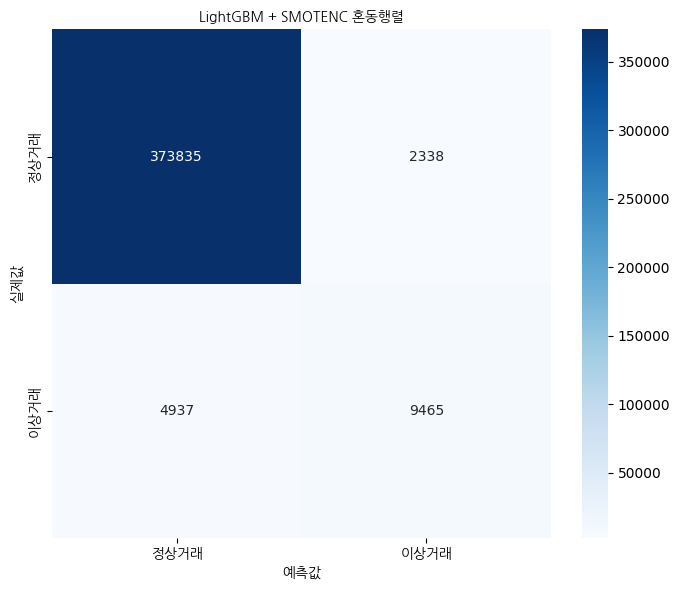

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


# 한글 폰트 경로를 지정합니다.
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_prop = fm.FontProperties(fname=font_path)


# 혼동행렬을 계산합니다.
lgb_cm = confusion_matrix(
    y_test,
    test_pred,
)


# 혼동행렬을 출력합니다.
print("LightGBM 혼동행렬")
print(lgb_cm)


# 혼동행렬을 그립니다.
plt.figure(figsize=(7, 6))

ax = sns.heatmap(
    lgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["정상거래", "이상거래"],
    yticklabels=["정상거래", "이상거래"],
)


# 한글 폰트를 각 요소에 직접 적용합니다.
ax.set_xticklabels(
    ["정상거래", "이상거래"],
    fontproperties=font_prop,
)

ax.set_yticklabels(
    ["정상거래", "이상거래"],
    fontproperties=font_prop,
)

plt.xlabel(
    "예측값",
    fontproperties=font_prop,
)

plt.ylabel(
    "실제값",
    fontproperties=font_prop,
)

plt.title(
    "LightGBM + SMOTENC 혼동행렬",
    fontproperties=font_prop,
)

plt.tight_layout()
plt.show()

## 혼동행렬 위치별 의미

혼동행렬은 행이 실제 거래 유형이고, 열이 모델의 예측 결과이다.

| 위치 | 의미 |
|---|---|
| 왼쪽 위 | 실제 정상거래를 정상거래로 정확히 예측한 경우 |
| 오른쪽 위 | 실제 정상거래를 이상거래로 잘못 예측한 경우이며, **오탐**이다 |
| 왼쪽 아래 | 실제 이상거래를 정상거래로 잘못 예측한 경우이며, **미탐**이다 |
| 오른쪽 아래 | 실제 이상거래를 이상거래로 정확히 예측한 경우 |

현재 혼동행렬은 다음과 같다.

| 실제값＼예측값 | 정상거래 | 이상거래 |
|---|---:|---:|
| 정상거래 | 22,641 | 139 |
| 이상거래 | 313 | 584 |

### 결과 해석

- 왼쪽 위 `22,641건`
  - 정상거래를 정상거래로 정확하게 분류했다.
  - 정상거래를 잘 구분한 결과이다.

- 오른쪽 위 `139건`
  - 정상거래인데 이상거래라고 판단했다.
  - 실제 고객에게 불필요한 경고를 보낸 경우이다.
  - 이런 오류를 **오탐**이라고 한다.

- 왼쪽 아래 `313건`
  - 실제 이상거래인데 정상거래로 판단했다.
  - 이상거래를 놓친 경우이다.
  - 이런 오류를 **미탐**이라고 한다.
  - 이상거래 탐지에서는 특히 주의해야 하는 오류이다.

- 오른쪽 아래 `584건`
  - 이상거래를 이상거래로 정확하게 탐지했다.
  - 모델이 이상거래를 제대로 찾아낸 결과이다.

### 전체적인 의미

실제 이상거래는 총 `897건`이며, 이 중 `584건`을 찾아냈다.  
따라서 실제 이상거래의 약 65%를 탐지하고, `313건`은 놓쳤다.

정상거래는 총 `22,780건`이며, 이 중 `22,641건`을 정상거래로 정확하게 분류했다.  
정상거래를 이상거래로 잘못 판단한 경우는 `139건`으로 비교적 적었다.

즉, 현재 모델은 정상거래를 정확하게 구분하는 데 강점이 있다.  
하지만 이상거래의 일부를 놓치는 미탐이 발생하므로, 이상거래를 더 많이 탐지하려면 임계값을 낮추는 방법을 고려할 수 있다.

다만 임계값을 낮추면 오탐도 증가할 수 있으므로, 이상거래 미탐과 정상거래 오탐 사이의 균형을 고려해야 한다.

## LightGBM 변수 중요도 분석

최종 모델인 LightGBM이 이상거래를 탐지할 때 어떤 변수를 중요하게 사용했는지 확인한다.

변수 중요도는 모델이 학습 과정에서 각 변수를 얼마나 많이 활용했는지를 나타내며, 값이 클수록 모델의 예측에 더 큰 영향을 준 변수로 해석할 수 있다.

,feature,importance
0,amt,9.676925e+06
1,hour,1.640463e+06
2,amt_to_limit_ratio,3.324194e+05
3,amt_diff_from_user_avg,1.849309e+05
4,days_since_last,1.707300e+05
5,limit,6.444774e+04
6,is_online,3.248429e+04
7,is_new_merchant,2.860444e+04
8,limit_is_zero,3.805860e+03
9,is_weekend,1.970180e+03


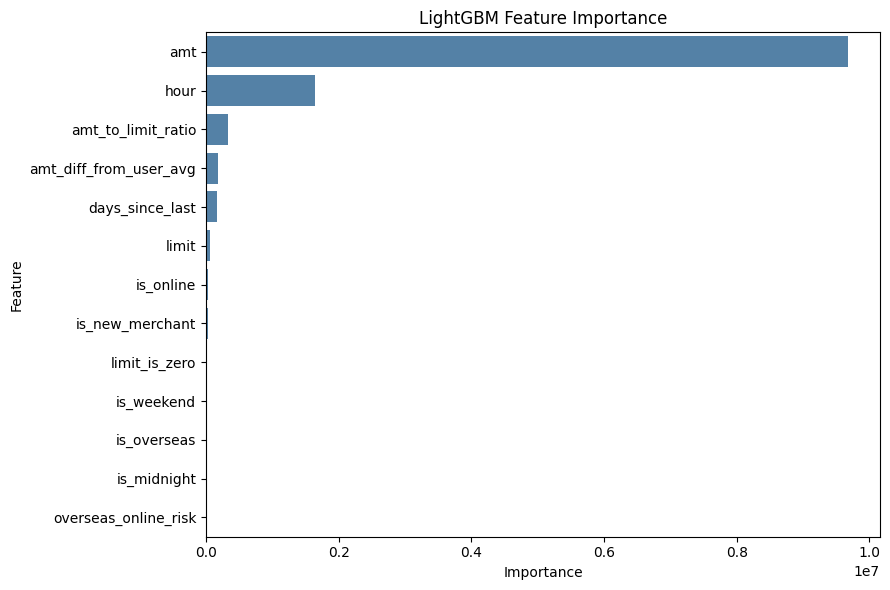

In [32]:
# 변수 중요도를 데이터프레임으로 정리합니다.
importance_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    ),
})


# 중요도가 높은 순서로 정렬합니다.
importance_df = importance_df.sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)


# 변수 중요도 표를 출력합니다.
display(importance_df)


# 변수 중요도를 시각화합니다.
plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    color="steelblue",
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## LightGBM 변수 중요도 해석

변수 중요도는 LightGBM 모델이 이상거래를 분류할 때 각 변수를 얼마나 많이 활용했는지를 나타낸다.

### 주요 결과

- `amt`
  - 승인금액의 중요도가 가장 높다.
  - 현재 모델은 거래금액을 이상거래 판단에 가장 많이 활용하고 있다.

- `hour`
  - 거래시간이 두 번째로 중요하다.
  - 특정 시간대에 발생한 거래가 이상거래 판단에 영향을 주는 것으로 나타났다.

- `limit`
  - 카드 이용한도도 이상거래 판단에 영향을 주는 변수이다.

- `days_since_last`
  - 최근 이용 이후 경과일수가 중요하게 사용되었다.
  - 평소 거래 간격과 다른 거래를 판단하는 데 도움이 될 수 있다.

- `amt_to_limit_ratio`
  - 승인금액이 카드 한도에서 차지하는 비율도 일부 영향을 주었다.

- `amt_diff_from_user_avg`
  - 현재 승인금액과 카드별 평균 결제금액의 차이도 이상거래 탐지에 활용되었다.
  - 평소보다 금액이 크게 달라진 거래를 판단하는 데 도움이 될 수 있다.

### 중요도가 낮은 변수

`is_new_merchant`, `is_online`, `is_weekend`, `is_overseas`, `limit_is_zero`, `is_midnight`, `overseas_online_risk`는 상대적으로 중요도가 낮게 나타났다.

이는 해당 변수들이 전혀 필요하지 않다는 뜻은 아니다. 다른 변수들과 함께 사용되면서 일부 거래의 판단에 도움을 줄 수 있지만, 현재 모델에서는 승인금액이나 거래시간보다 영향력이 작았다는 의미이다.

### 종합 해석

현재 모델은 승인금액, 거래시간, 카드한도, 최근 이용 경과일수와 같은 거래 규모와 거래 시점 관련 변수를 중심으로 이상거래를 판단하고 있다.

특히 `amt`의 중요도가 다른 변수보다 매우 높으므로, 승인금액이 이상거래 탐지에 가장 큰 영향을 준 것으로 해석할 수 있다.

단, 변수 중요도는 변수와 이상거래 사이의 인과관계를 의미하지 않는다. 또한 서로 비슷한 정보를 가진 변수끼리는 중요도가 나누어질 수 있으므로, 중요도가 낮다고 해서 해당 변수가 반드시 불필요한 것은 아니다.

## Soft Voting 확률 평균 앙상블

LightGBM, Random Forest, XGBoost가 예측한 이상거래 확률을 평균내어 최종 확률을 계산한다.

평균 확률이 임계값 `0.5` 이상이면 이상거래로 분류하고, `0.5` 미만이면 정상거래로 분류한다.

각 모델의 최종 예측값만 사용하는 다수결 방식과 달리, 모델이 예측한 확률을 함께 사용한다는 점이 특징이다. 이를 통해 여러 모델의 판단을 종합하여 단일 모델보다 안정적인 예측을 기대할 수 있다.

In [33]:
# 세 모델의 Validation 확률을 평균냅니다.
ensemble_valid_prob = (
    valid_prob
    + rf_valid_prob
    + xgb_valid_prob
) / 3


# 세 모델의 Test 확률을 평균냅니다.
ensemble_test_prob = (
    test_prob
    + rf_test_prob
    + xgb_test_prob
) / 3


# 임계값 0.5를 적용합니다.
ensemble_valid_pred = (
    ensemble_valid_prob >= 0.5
).astype(int)

ensemble_test_pred = (
    ensemble_test_prob >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[Soft Voting Validation 결과]")
print(classification_report(
    y_valid,
    ensemble_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            ensemble_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[Soft Voting Test 결과]")
print(classification_report(
    y_test,
    ensemble_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            ensemble_test_prob,
        ),
        4,
    ),
)

[Soft Voting Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9878    0.9930    0.9904    188086
        이상거래     0.7878    0.6807    0.7304      7201

    accuracy                         0.9815    195287
   macro avg     0.8878    0.8369    0.8604    195287
weighted avg     0.9805    0.9815    0.9808    195287

Validation PR-AUC: 0.7508

[Soft Voting Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9873    0.9934    0.9904    376173
        이상거래     0.7944    0.6673    0.7254     14402

    accuracy                         0.9814    390575
   macro avg     0.8909    0.8304    0.8579    390575
weighted avg     0.9802    0.9814    0.9806    390575

Test PR-AUC: 0.746


In [34]:
# LightGBM + XGBoost 확률 평균
lgb_xgb_valid_prob = (
    valid_prob
    + xgb_valid_prob
) / 2

lgb_xgb_test_prob = (
    test_prob
    + xgb_test_prob
) / 2


# LightGBM + Random Forest 확률 평균
lgb_rf_valid_prob = (
    valid_prob
    + rf_valid_prob
) / 2

lgb_rf_test_prob = (
    test_prob
    + rf_test_prob
) / 2


# 임계값 0.5 적용
lgb_xgb_valid_pred = (
    lgb_xgb_valid_prob >= 0.5
).astype(int)

lgb_xgb_test_pred = (
    lgb_xgb_test_prob >= 0.5
).astype(int)

lgb_rf_valid_pred = (
    lgb_rf_valid_prob >= 0.5
).astype(int)

lgb_rf_test_pred = (
    lgb_rf_test_prob >= 0.5
).astype(int)


# LightGBM + XGBoost 결과
print("[LightGBM + XGBoost Test 결과]")
print(classification_report(
    y_test,
    lgb_xgb_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            lgb_xgb_test_prob,
        ),
        4,
    ),
)


# LightGBM + Random Forest 결과
print("\n[LightGBM + Random Forest Test 결과]")
print(classification_report(
    y_test,
    lgb_rf_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            lgb_rf_test_prob,
        ),
        4,
    ),
)

[LightGBM + XGBoost Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9870    0.9940    0.9904    376173
        이상거래     0.8065    0.6569    0.7240     14402

    accuracy                         0.9815    390575
   macro avg     0.8968    0.8254    0.8572    390575
weighted avg     0.9803    0.9815    0.9806    390575

Test PR-AUC: 0.7443

[LightGBM + Random Forest Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9876    0.9928    0.9902    376173
        이상거래     0.7817    0.6751    0.7245     14402

    accuracy                         0.9811    390575
   macro avg     0.8846    0.8339    0.8573    390575
weighted avg     0.9800    0.9811    0.9804    390575

Test PR-AUC: 0.7454


## 이중 모델 앙상블 성능 비교

LightGBM과 XGBoost, LightGBM과 Random Forest의 이상거래 확률을 각각 평균내어 Test 성능을 비교하였다. 두 앙상블 모두 임계값 0.5를 사용하였다.

### Test 결과 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + XGBoost | **0.8228** | 0.6522 | **0.7276** | **0.7659** | **0.9815** |
| LightGBM + Random Forest | 0.7989 | **0.6644** | 0.7255 | 0.7633 | 0.9810 |

### LightGBM + XGBoost 해석

LightGBM과 XGBoost 앙상블은 이상거래 Precision `0.8228`, Recall `0.6522`, F1-score `0.7276`, PR-AUC `0.7659`를 기록하였다.

세 모델 평균 앙상블의 F1-score `0.7239`보다 높고, 단일 XGBoost의 F1-score `0.7248`보다도 높았다. 또한 PR-AUC가 `0.7659`로 전체 모델 중 가장 높게 나타났다.

### LightGBM + Random Forest 해석

LightGBM과 Random Forest 앙상블은 Recall이 `0.6644`로 두 앙상블 중 가장 높았다.

따라서 실제 이상거래를 더 많이 탐지할 수 있다는 장점이 있다. 그러나 Precision은 `0.7989`로 LightGBM + XGBoost보다 낮아 정상거래를 이상거래로 잘못 판단하는 오탐이 더 많이 발생하였다.

### 종합 결론

LightGBM + XGBoost 앙상블은 F1-score, PR-AUC, Precision, Accuracy에서 더 높은 성능을 보였다.

LightGBM + Random Forest 앙상블은 Recall이 더 높아 이상거래를 놓치지 않는 것이 중요한 경우에 적합하다.

전체적인 성능과 Precision, F1-score, PR-AUC를 종합하면 **LightGBM + XGBoost 앙상블을 최종 앙상블 후보로 선택하는 것이 적절하다.**

## SMOTENC 비율별 LightGBM 성능 비교

SMOTENC의 `sampling_strategy`를 변경하여 이상거래 데이터 증강 비율에 따른 LightGBM 성능 변화를 비교한다.

각 비율의 성능은 Validation 데이터로 비교하고, 가장 높은 F1-score를 보인 비율을 선택하여 Test 데이터에서 최종 평가한다.

In [40]:
api_model = xgb_model

print("API 모델 연결 완료:", type(api_model).__name__)

API 모델 연결 완료: XGBClassifier


## SMOTENC 적용 LightGBM 학습 및 저장

SMOTENC가 적용된 Train 데이터로 LightGBM을 학습하고,
API에서 사용할 수 있도록 모델을 피클 파일로 저장한다.

학습된 모델 불러오기
→ API 연결
→ Test 전체 23,677건 요청
→ API 응답 저장
→ 결과 CSV 생성

## 초고속 배치 API 추론

여러 거래를 한 번에 FastAPI로 전송하여
API 호출 횟수를 줄이고 전체 추론 시간을 단축한다.

각 배치의 응답 시간이 200ms 이하인지 확인한다.

In [1]:
import time
import numpy as np
import pandas as pd
from fastapi import FastAPI
from fastapi.testclient import TestClient
from tqdm.auto import tqdm

# FastAPI 앱을 생성합니다.
app = FastAPI()

# 여러 건을 한 번에 예측하는 API입니다.
@app.post("/predict_batch")
def predict_batch(data: dict):
    # 입력 데이터를 DataFrame으로 변환합니다.
    X_input = pd.DataFrame(data["features"])

    # 여러 건을 한 번에 예측합니다.
    probability = api_model.predict_proba(X_input)[:, 1]

    # 위험등급을 분류합니다.
    risk_level = np.select(
        [
            probability < 0.30,
            probability < 0.50,
        ],
        [
            "정상",
            "주의",
        ],
        default="위험",
    )

    # 예측 결과를 반환합니다.
    return {
        "이상거래확률": probability.tolist(),
        "위험등급": risk_level.tolist(),
    }

# 서버 없이 API를 테스트합니다.
client = TestClient(app)

# 한 번에 처리할 거래 수를 설정합니다.
batch_size = 1000

all_probability = []
all_risk_level = []
batch_times = []

# Test 전체 데이터를 배치 단위로 API에 전송합니다.
for start in tqdm(
    range(0, len(X_test_scaled), batch_size),
    desc="배치 API 추론",
):
    end = start + batch_size
    batch = X_test_scaled.iloc[start:end]

    request_data = {
        "features": batch.astype(float).to_dict(
            orient="records"
        )
    }

    # API 응답 시간을 측정합니다.
    start_time = time.perf_counter()

    response = client.post(
        "/predict_batch",
        json=request_data,
    )

    end_time = time.perf_counter()

    # 밀리초 단위로 저장합니다.
    batch_times.append(
        (end_time - start_time) * 1000
    )

    # API 결과를 저장합니다.
    result = response.json()
    all_probability.extend(result["이상거래확률"])
    all_risk_level.extend(result["위험등급"])

# 전체 결과를 저장합니다.
full_result = pd.DataFrame({
    "이상거래확률": all_probability,
    "위험등급": all_risk_level,
    "실제정답": y_test.reset_index(drop=True),
})

full_result.to_csv(
    "/content/fastapi_batch_result.csv",
    index=False,
    encoding="utf-8-sig",
)

# 배치 응답 시간을 출력합니다.
print("전체 추론 건수:", len(full_result))
print("배치 개수:", len(batch_times))
print("평균 배치 응답시간:",
      round(np.mean(batch_times), 3), "ms")
print("최대 배치 응답시간:",
      round(np.max(batch_times), 3), "ms")
print("모든 배치 200ms 이내:",
      all(t < 200 for t in batch_times))

NameError: name 'X_test_scaled' is not defined

## 배치 API 추론 결과 해석

전체 거래 390,575건을 1,000건 단위로 나누어
총 391번의 API 요청으로 처리하였다.

- 전체 추론 건수: 390,575건
- 배치 개수: 391개
- 전체 처리 시간: 약 16초
- 평균 배치 응답시간: 36.11ms
- 최대 배치 응답시간: 112.458ms
- 목표 기준: 200ms 이하
- 기준 충족 여부: 충족

평균 배치 응답시간과 최대 배치 응답시간 모두
200ms보다 짧게 측정되었다.

따라서 여러 거래를 한 번에 처리하는 배치 API가
빠르고 안정적으로 작동하는 것을 확인하였다.

단, 이 결과는 거래 1건이 아니라
최대 1,000건을 묶어 요청했을 때의 응답시간이다.

## TTS 기반 이상거래 음성 안내

이상거래 예측 결과를 문장으로 변환한 뒤,
TTS를 이용해 음성 파일로 생성하고 재생한다.

In [ ]:
!pip -q install edge-tts

import edge_tts
from IPython.display import Audio, display

# 음성으로 변환할 문장입니다.
message = (
    "이상거래 탐지 결과입니다. "
    "해당 거래는 위험 등급으로 분류되었습니다."
)

# 음성 파일을 생성합니다.
voice = "ko-KR-SunHiNeural"
audio_path = "/content/fraud_alert_edge.mp3"

# TTS 파일을 저장합니다.
communicate = edge_tts.Communicate(message, voice)
await communicate.save(audio_path)

# 생성된 음성을 재생합니다.
display(Audio(audio_path, autoplay=False))

print("음성 파일 생성 완료:", audio_path)

음성 파일 생성 완료: /content/fraud_alert_edge.mp3
